# Minimal drone RL — PPO with a PyTorch RNN

Load `rnn_model/rnn_model_robust`, check the environment, train, and evaluate.
Restart the kernel after editing `lib`, then run all cells.
Run from `rl_interface/` or the project root.

The trained RNN predicts normalized acceleration one step at a time.
`DroneEnv` handles denormalization, dynamics, observations, reward, and outcomes.
It carries the RNN hidden tensor between steps and clears it at each reset.


In [1]:
# Run once if needed, then restart the kernel:
# %pip install gymnasium stable-baselines3 numpy matplotlib scipy

import ast
import io
import zipfile
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.results_plotter import load_results

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "rnn_model/rnn_training.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the drone project or rl_interface/ to find rnn_model/rnn_training.py")
sys.path.insert(0, str(PROJECT_ROOT / "rl_interface"))
from lib.droneEnv import DroneEnv, PARAMS, mission, run_episode, evaluate

SEED = 0
TOTAL_TIMESTEPS = 500000
LOG_DIR = PROJECT_ROOT / "rl_interface" / "logs" / f"ppo_rnn_error_{time.strftime('%Y%m%d_%H%M%S')}"
MODEL_PATH = LOG_DIR / "ppo_drone_rnn"
print("Run directory:", LOG_DIR)
torch.set_num_threads(1)

Run directory: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/ppo_rnn_error_20261103_134042


## Load the trained RNN and head

Use `ModelNN` from `rnn_model/rnn_training.py`, with its 32-hidden-unit RNN
and linear head. Load only the class definition: importing the entire script
would also read its CSVs and start 700 training epochs.

`rnn_model/rnn_model_robust` contains an extracted PyTorch state dict.
Repack its existing files in memory so `torch.load(weights_only=True)` can
read the checkpoint. Strict loading checks all RNN and head weights.

The existing library runs `out, h = model.rnn(x, h)` followed by `model.head(out)`.
Each episode starts with `h=None`; subsequent steps reuse the returned hidden
tensor. Each parallel environment keeps its own hidden tensor. No command
history or full-sequence replay is needed.


In [2]:
training_path = PROJECT_ROOT / "rnn_model/rnn_training.py"
definition = next(
    node for node in ast.parse(training_path.read_text()).body
    if isinstance(node, ast.ClassDef) and node.name == "ModelNN"
)
exec(compile(ast.Module(body=[definition], type_ignores=[]), str(training_path), "exec"))

model_path = PROJECT_ROOT / "rnn_model/rnn_model_robust"
buffer = io.BytesIO()
with zipfile.ZipFile(buffer, "w", strict_timestamps=False) as archive:
    for file in sorted(model_path.rglob("*")):
        if file.is_file():
            archive.write(file, f"checkpoint/{file.relative_to(model_path).as_posix()}")
buffer.seek(0)
weights = torch.load(buffer, map_location="cpu", weights_only=True)

acceleration_rnn = ModelNN(1, 1, "RNN", 32, 1)
load_result = acceleration_rnn.load_state_dict(weights, strict=True)
acceleration_rnn.eval().requires_grad_(False)

print("Model:", model_path)
print("Load:", load_result)
print("RNN:", acceleration_rnn.rnn)
print("Head:", acceleration_rnn.head)


Model: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rnn_model/rnn_model_robust
Load: <All keys matched successfully>
RNN: RNN(1, 32, batch_first=True)
Head: Linear(in_features=32, out_features=1, bias=True)


## 1. Environment

The policy now observes `[z - z_ref, vz, az]`: altitude error, vertical velocity,
and the latest available acceleration, all in physical units. The physical
state remains `[z, vz, az]`. MATLAB constructs the same three inputs.
The airborne start, standardized actions in `[-3, 3]`, RNN inference, 0.05 s
sampling period, and 10 s mission are unchanged.

Only a soft touchdown during the landing phase succeeds. Early touchdown,
crash, ceiling exit, and the mission deadline without landing are failures.
The running reward remains `1 - 2*abs(z-z_ref) - 0.1*vz**2 - 0.01*u**2 - 0.05*(u-u_prev)**2`;
success gives +100 and failure gives -100.

The target affects the first input directly without adding observations or history.
Retrain from scratch: checkpoints trained with absolute altitude have different
input semantics despite also accepting three values.

In [3]:
env = DroneEnv(rnn_model=acceleration_rnn)
check_env(env)
obs, info = env.reset(seed=SEED)
print("Observation:", obs, env.observation_space)
print("Action:", env.action_space)
print("check_env: OK")


Observation: [ 0.     0.    -9.816] Box([ -inf  -20. -100.], [ inf  20. 100.], (3,), float32)
Action: Box(-3.0, 3.0, (1,), float32)
check_env: OK


/home/rayan768/venvs/main_env/lib/python3.13/site-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


In [4]:
env.reset(seed=SEED)
print(f"Initial state: {env.state}, t={env.t:.2f}, mission={mission(env.t):.2f}")

a = np.array([0.6], dtype=np.float32)
for _ in range(100):
    obs, reward, terminated, truncated, info = env.step(a)
    if terminated or truncated:
        break

print(f"State: {env.state}, t={env.t:.2f}, mission={mission(env.t):.2f}, outcome={info['outcome']}")


Initial state: [ 0.     0.    -9.816], t=0.00, mission=0.00
State: [ 5.2018986 10.366705  10.900168 ], t=1.25, mission=0.00, outcome=lost


## 2. Baselines

Compare random and zero commands with a feedback controller using the same
`[z - z_ref, vz, az]` inputs as PPO. The feedback controller now follows the
mission reference instead of holding a fixed altitude.
Its hover command and local acceleration gain were measured from the loaded
RNN: approximately 0.23056 and 39.91 in the current standardized command units.

Reset is deterministic, so repeated deterministic flights do not measure robustness.
The library stops each flight on termination; a longer step limit cannot prevent a crash.

In [5]:
rng = np.random.default_rng(SEED)

def random_policy(obs):
    return rng.uniform(env.action_space.low, env.action_space.high).astype(np.float32)

def zero_policy(obs):
    return np.zeros(env.action_space.shape, dtype=np.float32)

def feedback_policy(obs):
    error, vz, az = obs
    u = 0.23056 + (-8.0 * error - 8.0 * vz - 2.0 * az) / 39.91
    return np.clip(np.array([u], dtype=np.float32), env.action_space.low, env.action_space.high)

for name, policy in [("Random", random_policy), ("Zero", zero_policy), ("Feedback", feedback_policy)]:
    print(f"{name:12s}", end=" ")
    evaluate(env, policy, n=10, seed=100)

Random       mean return:  -134.8 ±  55.5 | landed: 0/10
Zero         mean return:   -97.6 ±   0.0 | landed: 0/10
Feedback     mean return:   220.2 ±   0.0 | landed: 10/10


## 3. Train PPO

Train a fresh PPO agent for 500k steps using the error observation.
One CPU thread reduces overhead for these small networks.
Each run uses a separate log directory for its checkpoint and episode returns.


In [6]:
train_env = make_vec_env(
    lambda: DroneEnv(rnn_model=acceleration_rnn), n_envs=10, seed=SEED, monitor_dir=str(LOG_DIR)
)
agent = PPO(
    "MlpPolicy", train_env, seed=SEED, device="cpu",
    learning_rate=1e-4, n_steps=256, batch_size=128, verbose=0,
)
start = time.perf_counter()
agent.learn(total_timesteps=TOTAL_TIMESTEPS)
print(f"Trained for {agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s")
train_env.close()


Trained for 501,760 steps in 185.8 s


## 4. Evaluate and inspect the flight

Evaluate the current PPO policy alongside the feedback controller on the same mission.
Report flight duration, mission altitude MAE, and RMS command changes.
Plot the full 10 s mission with terminal markers, then zoom into any short failed flights.


Policy         Outcome    Time (s)    Return  Mission MAE  RMS delta-u
Feedback       landed         8.95     220.2       0.1610       0.0619
PPO            timeout       10.00      37.0       0.1264       0.8853


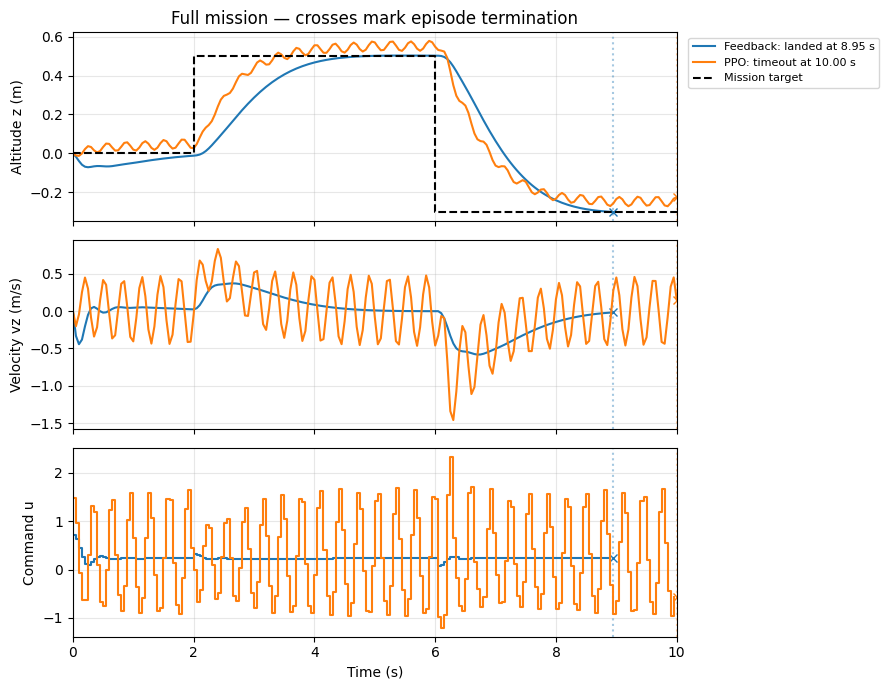

In [7]:
def ppo_policy(obs):
    return agent.predict(obs, deterministic=True)[0]

eval_env = DroneEnv(rnn_model=acceleration_rnn)
policies = [("Feedback", feedback_policy), ("PPO", ppo_policy)]

flights = {}
print(f"{'Policy':14s} {'Outcome':9s} {'Time (s)':>9s} {'Return':>9s} {'Mission MAE':>12s} {'RMS delta-u':>12s}")
for name, policy in policies:
    states, actions, total, outcome = run_episode(eval_env, policy, seed=100)
    t = np.arange(len(states)) * PARAMS.dt
    commands = np.asarray(actions).reshape(-1)
    target = np.array([mission(float(ti)) for ti in t[1:]])
    mae = np.mean(np.abs(states[1:, 0] - target))
    rms_du = np.sqrt(np.mean(np.diff(np.r_[0.0, commands]) ** 2))
    flights[name] = (t, states, commands, outcome)
    print(f"{name:14s} {outcome:9s} {t[-1]:9.2f} {total:9.1f} {mae:12.4f} {rms_du:12.4f}")

horizon = eval_env.max_steps * PARAMS.dt

def plot_flights(selected, end_time, title):
    fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
    for name, (t, states, commands, outcome) in selected.items():
        label = f"{name}: {outcome} at {t[-1]:.2f} s"
        line, = axes[0].plot(t, states[:, 0], label=label)
        color = line.get_color()
        axes[1].plot(t, states[:, 1], color=color)
        axes[2].step(t[:-1], commands, where="post", color=color)
        for ax, values in zip(axes, [states[:, 0], states[:, 1], commands]):
            ax.plot(t[-1], values[-1], "x", color=color)
            ax.axvline(t[-1], color=color, linestyle=":", alpha=0.4)
    reference_t = np.arange(eval_env.max_steps + 1) * PARAMS.dt
    axes[0].step(reference_t, [mission(float(ti)) for ti in reference_t],
                 where="post", color="black", linestyle="--", label="Mission target")
    for ax, label in zip(axes, ["Altitude z (m)", "Velocity vz (m/s)", "Command u"]):
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    axes[0].set_title(title)
    axes[2].set(xlabel="Time (s)", xlim=(0, end_time))
    fig.tight_layout()
    plt.show()

plot_flights(flights, horizon, "Full mission — crosses mark episode termination")
short_failures = {
    name: flight for name, flight in flights.items()
    if flight[3] in ("crashed", "lost", "timeout") and flight[0][-1] < horizon - PARAMS.dt
}
if short_failures:
    end_time = min(horizon, max(flight[0][-1] for flight in short_failures.values()) + 0.25)
    plot_flights(short_failures, end_time, "Short failed flights — zoom")
eval_env.close()

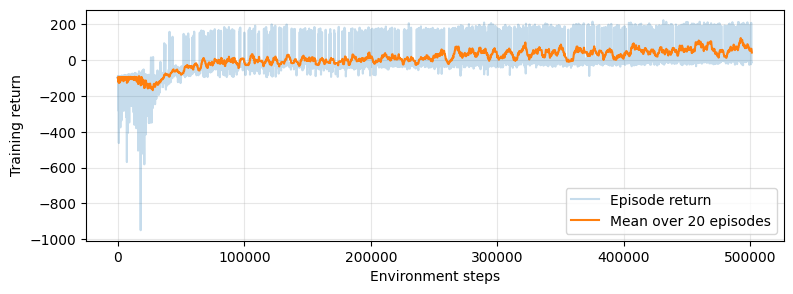

In [8]:
history = load_results(str(LOG_DIR))
returns = history["r"].to_numpy()
steps = history["l"].cumsum().to_numpy()
window = min(20, len(returns))

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(steps, returns, alpha=0.25, label="Episode return")
if window:
    smoothed = np.convolve(returns, np.ones(window) / window, mode="valid")
    ax.plot(steps[window - 1:], smoothed, label=f"Mean over {window} episodes")
ax.set(xlabel="Environment steps", ylabel="Training return")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


## 5. Save and optional MATLAB export

Save the newly trained PPO agent in this run's log directory; old checkpoints
are retained. Reload with `PPO.load(MODEL_PATH)`.
Set `EXPORT_MATLAB=True` to use the existing exporter.

Python and `rl_controller.m` both construct `[z - z_ref, vz, az]`; the MATLAB
acceleration input is named `az_prev`. The exported measurement now carries
the same available acceleration as the Python observation, without an extra delay.
MATLAB's mission matches Python: 0 m before 2 s, 0.5 m before 6 s, then -0.3 m.
No Simulink blocks or wiring are changed. Standardized actions remain `[-3, 3]`;
physical commands remain `u * PARAMS.sigma_u + PARAMS.mean_u`.

In [9]:
agent.save(MODEL_PATH)
print("Saved:", MODEL_PATH.with_suffix(".zip"))

EXPORT_MATLAB = False
if EXPORT_MATLAB:
    from export_policy import export_for_matlab
    export_env = DroneEnv(rnn_model=acceleration_rnn)
    export_for_matlab(agent, export_env)
    export_env.close()
env.close()

Saved: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/rl_interface/logs/ppo_rnn_error_20261103_134042/ppo_drone_rnn.zip
